# **2. LOGISTIC REGRESSION**
---

## **1. Thiết lập môi trường và nạp dữ liệu MNIST đã tiền xử lý**

In [2]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [4]:
# 0. Xác định thư mục gốc dự án và thêm src vào sys.path
try:
    from IPython.display import display
except ImportError:
    display = print

# 1. Xác định PROJECT_ROOT dựa vào pyproject.toml
PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT / "src" / "pattern_recognition" / "config.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (chứa pyproject.toml).")
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_PATH = str(PROJECT_ROOT / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

# 2. Khởi tạo các thư mục lưu trữ của đồ án
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
for output_dir in (FIGURES_DIR, RESULTS_DIR, ARTIFACTS_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

# 3. Cố định tính tái lập ngẫu nhiên từ cấu hình chung
from pattern_recognition.config import SEED
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120
print(f"Thiết lập môi trường thành công! SEED cố định = {SEED}")


Thiết lập môi trường thành công! SEED cố định = 42


In [5]:
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "mnist_processed.npz"
data = np.load(DATA_PATH)
X_train = data["X_train_minmax"]  
y_train = data["y_train"]        
X_val   = data["X_val_minmax"]   
y_val   = data["y_val"]           
X_test  = data["X_test_minmax"]   
y_test  = data["y_test"]         

# Kiểm tra kích thước và miền giá trị của từng tập dữ liệu.
print(f"Nạp dữ liệu thành công từ: '{DATA_PATH.name}'")
print(f"Tập Huấn luyện (Train)     : X = {tuple(X_train.shape)} | y = {tuple(y_train.shape)} | Miền giá trị: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"Tập Kiểm định  (Validation): X = {tuple(X_val.shape)}   | y = {tuple(y_val.shape)}   | Miền giá trị: [{X_val.min():.2f}, {X_val.max():.2f}]")
print(f"Tập Kiểm thử   (Test)      : X = {tuple(X_test.shape)}  | y = {tuple(y_test.shape)}  | Miền giá trị: [{X_test.min():.2f}, {X_test.max():.2f}]")


Nạp dữ liệu thành công từ: 'mnist_processed.npz'
Tập Huấn luyện (Train)     : X = (50000, 784) | y = (50000,) | Miền giá trị: [0.00, 1.00]
Tập Kiểm định  (Validation): X = (10000, 784)   | y = (10000,)   | Miền giá trị: [0.00, 1.00]
Tập Kiểm thử   (Test)      : X = (10000, 784)  | y = (10000,)  | Miền giá trị: [0.00, 1.00]


## **2. Cơ sở lý thuyết: Logistic Regression tuyến tính và One-vs-Rest**


### **2.1. Từ ảnh đến điểm số dự đoán**

Mỗi ảnh MNIST được biểu diễn thành vector $\mathbf{x}$ gồm 784 giá trị pixel. Logistic Regression gán một trọng số cho mỗi pixel để học pixel nào có ích khi nhận diện một chữ số. Mô hình cộng các đóng góp đó để tạo điểm số:

$$
z = \mathbf{x}\mathbf{w} + b
$$

Trong đó $\mathbf{w}$ là các trọng số, còn $b$ là bias — giúp mô hình linh hoạt điều chỉnh ngưỡng phân loại. Trong code, bias có thể được gộp vào vector đặc trưng bằng cách thêm một giá trị `1` vào cuối $\mathbf{x}$:

$$
\tilde{\mathbf{x}} = [\mathbf{x}, 1],
\qquad z = \tilde{\mathbf{x}}\mathbf{w}
$$

Khác với Naïve Bayes, mô hình không cố mô tả pixel của từng lớp xuất hiện như thế nào; thay vào đó, Logistic Regression học trực tiếp cách phân biệt các lớp.



### **2.2. Sigmoid: chuyển điểm số thành xác suất nhị phân**

Với bài toán chỉ có hai lớp, hàm Sigmoid chuyển điểm số $z$ thành giá trị từ 0 đến 1:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Có thể hiểu giá trị này là mức độ mô hình tin rằng ảnh thuộc lớp dương: càng gần 1 thì càng nghiêng về lớp dương, càng gần 0 thì càng nghiêng về lớp âm.

Khi tính toán trên máy tính, ta dùng dạng tương đương dưới đây để tránh số mũ bị quá lớn:

$$
\sigma(z) =
\begin{cases}
\dfrac{1}{1 + e^{-z}}, & z \ge 0 \\[6pt]
\dfrac{e^z}{1 + e^z}, & z < 0
\end{cases}
$$



### **2.3. Đo lỗi dự đoán và điều chuẩn L2**

Để huấn luyện bộ phân loại nhị phân, nhãn được biểu diễn thành $t \in \{0,1\}$: `1` nếu mẫu thuộc lớp đang xét và `0` nếu không thuộc lớp đó. Hàm Binary Cross-Entropy đo mức độ dự đoán lệch khỏi nhãn thật:

$$
L(\mathbf{w}) =
-\frac{1}{N}\sum_{i=1}^{N}
\left[
t_i\ln(p_i) + (1-t_i)\ln(1-p_i)
\right]
$$

Trong đó $p_i = \sigma(z_i)$ là xác suất dự đoán cho mẫu thứ $i$. Dự đoán càng sai nhưng càng tự tin thì mức phạt càng lớn.

Mô hình còn có thể thêm điều chuẩn L2 để hạn chế trọng số quá lớn:

$$
J(\mathbf{w}) =
\frac{1}{N}\sum_{i=1}^{N}
\left[\ln(1+e^{z_i}) - t_i z_i\right]
+ \frac{\lambda}{2}\sum_{j=1}^{d}w_j^2
$$

Số hạng đầu là lỗi dự đoán; số hạng sau phạt các trọng số lớn. $\lambda$ điều chỉnh mức phạt: $\lambda$ càng lớn thì mô hình càng bị hạn chế tạo trọng số lớn. Bias thường không bị phạt để mô hình vẫn có thể tự do điều chỉnh ngưỡng phân loại.

Biểu thức trong code có thể viết gọn và ổn định hơn bằng `np.logaddexp(0, z)`, tương đương với $\ln(1+e^z)$ nhưng hạn chế lỗi số học.



### **2.4. Gradient Descent: điều chỉnh trọng số để giảm lỗi**

Gradient cho biết cần thay đổi từng trọng số theo hướng nào để hàm mất mát giảm. Với toàn bộ $N$ mẫu, gradient có dạng:

$$
\nabla_{\mathbf{w}}J =
\frac{1}{N}\tilde{\mathbf{X}}^T(\mathbf{p}-\mathbf{t})
+ \lambda(\mathbf{m}\odot\mathbf{w})
$$

Trong đó $\mathbf{p}$ là các xác suất dự đoán, $\mathbf{t}$ là các nhãn thật, còn $\mathbf{m}$ là mặt nạ không phạt bias. Ký hiệu $\odot$ là phép nhân từng phần tử.

Sau mỗi vòng lặp, trọng số được cập nhật theo hướng ngược với gradient:

$$\mathbf{w}^{(k+1)}=\mathbf{w}^{(k)} - \eta\nabla_{\mathbf{w}}J$$

$\eta$ là learning rate, quyết định độ lớn mỗi bước cập nhật. Quá trình lặp đến khi đạt `max_epochs` hoặc mức thay đổi của hàm mất mát giữa hai vòng liên tiếp nhỏ hơn `tol`.



### **2.5. Nhận diện 10 chữ số bằng One-vs-Rest**

Sigmoid phân loại hai nhóm, trong khi MNIST có 10 chữ số. One-vs-Rest (OvR) giải quyết việc này bằng cách huấn luyện 10 bộ phân loại nhị phân:

- Bộ thứ nhất học phân biệt **chữ số 0** với **tất cả chữ số còn lại**.
- Bộ thứ hai học phân biệt **chữ số 1** với **tất cả chữ số còn lại**.
- Tiếp tục như vậy đến chữ số 9.

Với một ảnh mới, mỗi bộ phân loại tạo ra một điểm số:

$$
f_c(\mathbf{x}) = [\mathbf{x},1]\mathbf{w}_c,
\qquad c \in \{0,\dots,9\}
$$

Mô hình dự đoán chữ số có điểm số cao nhất:

$$
\hat{y} = \arg\max_{c\in\{0,\dots,9\}} f_c(\mathbf{x})
$$

Nếu cần một vector giá trị không âm có tổng bằng 1 cho mô hình kết hợp, có thể chuẩn hóa các điểm số bằng Softmax:

$$
q_c = \frac{e^{f_c(\mathbf{x})}}{\sum_{j=0}^{9}e^{f_j(\mathbf{x})}}
$$

Các giá trị $q_c$ hữu ích như điểm số đã chuẩn hóa, nhưng với OvR chúng **không mặc nhiên là xác suất đã hiệu chỉnh**. Khi chỉ cần dự đoán nhãn, quy tắc chọn điểm số cao nhất ở trên là đủ.


## **3. Cài đặt Logistic Regression & Kiểm thử nhị phân**

In [5]:
def add_bias(X):
    return np.hstack([X, np.ones((X.shape[0], 1), dtype=X.dtype)])


def sigmoid(z):
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

print("Các hàm toán học bổ trợ (add_bias, sigmoid) đã sẵn sàng!")


Các hàm toán học bổ trợ (add_bias, sigmoid) đã sẵn sàng!


In [6]:
class LogisticRegressionNP:
    def __init__(self, eta=1.0, lam=1e-4, max_epochs=40, tol=1e-7):
        self.eta = eta               
        self.lam = lam                
        self.max_epochs = max_epochs  
        self.tol = tol             

    def fit(self, X, y):
        Xb = add_bias(X)
        t = (y > 0).astype(float)
        N, d = Xb.shape
        mask = np.ones(d)
        mask[-1] = 0.0
        self.w_ = np.zeros(d)
        self.loss_ = [] 
        
        for epoch in range(self.max_epochs):
            z = Xb @ self.w_                                                                  
            p = sigmoid(z)                                                                    
            loss = np.mean(np.logaddexp(0, z) - t * z) + 0.5 * self.lam * np.sum((mask * self.w_) ** 2)  
            grad = (Xb.T @ (p - t)) / N + self.lam * (mask * self.w_)                      
            self.w_ = self.w_ - self.eta * grad                                           
            self.loss_.append(loss)
            
            # Điều kiện dừng sớm khi độ suy giảm hàm mất mát nhỏ hơn ngưỡng tol
            if epoch > 0 and abs(self.loss_[-2] - loss) < self.tol:
                break
        return self

    def decision_function(self, X):
        """Tính điểm số hàm quyết định tuyến tính f(x) = x @ w."""
        return add_bias(X) @ self.w_

    def predict_proba(self, X):
        """Tính xác suất mẫu thuộc về lớp dương P(y = +1 | x) qua hàm Sigmoid."""
        return sigmoid(self.decision_function(X))

    def predict(self, X):
        """Dự đoán nhãn nhị phân: nếu f(x) >= 0 gán nhãn +1, ngược lại gán nhãn -1."""
        return np.where(self.decision_function(X) >= 0, 1, -1)


class OneVsRest:
    def __init__(self, eta=1.0, lam=1e-4, max_epochs=40, tol=1e-7):
        self.eta = eta               
        self.lam = lam                
        self.max_epochs = max_epochs 
        self.tol = tol                

    def fit(self, X, y):
        self.classes_ = np.unique(y) 
        K = len(self.classes_)       
        N, d = X.shape               
        Xb = add_bias(X)
        
        T = np.zeros((N, K), dtype=float)
        for idx, c in enumerate(self.classes_):
            T[:, idx] = (y == c).astype(float)
        mask = np.ones((d + 1, 1), dtype=float)
        mask[-1] = 0.0
        
        self.W_ = np.zeros((d + 1, K), dtype=float)
        self.loss_history_ = []  
        
        for epoch in range(self.max_epochs):
            Z = Xb @ self.W_
            P = sigmoid(Z)   
            
            loss_k = np.mean(np.logaddexp(0, Z) - T * Z, axis=0) + 0.5 * self.lam * np.sum((mask * self.W_) ** 2, axis=0)
            mean_loss = float(np.mean(loss_k))
            self.loss_history_.append(mean_loss)
            
            grad = (Xb.T @ (P - T)) / N + self.lam * (mask * self.W_)
            self.W_ -= self.eta * grad  # Cập nhật song song cả 10 bộ trọng số
            
            # Dừng sớm nếu hàm mất mát không đổi đáng kể
            if epoch > 0 and abs(self.loss_history_[-2] - mean_loss) < self.tol:
                break
            
        class BinaryModelView:
            def __init__(self, w, loss):
                self.w_ = w
                self.loss_ = loss
            def decision_function(self, X_in):
                return add_bias(X_in) @ self.w_
                
        self.models_ = [BinaryModelView(self.W_[:, i], self.loss_history_) for i in range(K)]
        return self

    def decision_function(self, X):
        """Trả về ma trận điểm số quyết định kích thước (N, 10) của 10 chữ số."""
        return add_bias(X) @ self.W_

    def predict_proba(self, X):
        """
        Chuyển đổi điểm số tuyến tính thành phân phối xác suất đa lớp bằng hàm Softmax.
        """
        scores = self.decision_function(X)
        z_max = np.max(scores, axis=1, keepdims=True)  # Ổn định số học tránh tràn số exp
        ez = np.exp(scores - z_max)
        return ez / np.sum(ez, axis=1, keepdims=True)

    def predict(self, X):
        """Quy tắc quyết định đa lớp: Chọn chữ số có điểm số decision_function cao nhất (argmax)."""
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]

print("✔ Lớp LogisticRegressionNP và OneVsRest đã sẵn sàng!")


✔ Lớp LogisticRegressionNP và OneVsRest đã sẵn sàng!


Cell dưới đây lấy 100 ảnh đầu tiên từ tập Train và chuyển nhãn thành bài toán nhị phân: **số 0 (`+1`)** và **không phải số 0 (`-1`)**. Mô hình được huấn luyện tối đa 10 epoch, sau đó so sánh hàm mất mát được ghi nhận ở lần đầu và lần cuối.

Nếu loss giảm, điều đó cho thấy mô hình đã giảm lỗi trên tập mẫu thử này. Đây chỉ là kiểm tra nhanh hoạt động của quá trình huấn luyện, **không chứng minh mô hình đã hội tụ hoặc đạt hiệu quả tốt**.

In [ ]:
# Lấy 100 ảnh đầu tiên và tạo nhãn nhị phân: số 0 (+1), các số khác (-1)
X_sub = X_train[:100]
y_sub = np.where(y_train[:100] == 0, 1, -1)

# Huấn luyện thử tối đa 10 epoch
model_test = LogisticRegressionNP(eta=0.5, lam=1e-4, max_epochs=10)
model_test.fit(X_sub, y_sub)

# So sánh loss được ghi nhận ở lần đầu và lần cuối
loss_first = model_test.loss_[0]
loss_last = model_test.loss_[-1]

print(f"Số mẫu thử: {len(y_sub)}")
print(f"Loss lần ghi đầu: {loss_first:.4f}")
print(f"Loss lần ghi cuối: {loss_last:.4f}")
print(f"Loss có giảm: {'Có' if loss_last < loss_first else 'Không'}")

Số mẫu thử: 100
Loss lần ghi đầu: 0.6931
Loss lần ghi cuối: 0.1026
Loss có giảm: Có


## **4. Khảo sát Learning Rate $\eta$ và số epoch**

Trong thí nghiệm này, chúng ta tập trung khảo sát **Learning Rate (`eta`)** và **số epoch tối đa (`max_epochs`)**. `eta` quyết định độ lớn mỗi bước cập nhật trọng số, còn `max_epochs` giới hạn số lần mô hình học qua tập Train. Hai tham số này tác động trực tiếp đến tốc độ và mức độ học của mô hình.

Để tập trung vào ảnh hưởng của `eta` và `max_epochs`, `lam` được giữ cố định ở mức nhỏ (`1e-4`), còn `tol` được giữ nguyên làm ngưỡng dừng sớm. Đây là lựa chọn phạm vi cho thí nghiệm, không có nghĩa `lam` và `tol` không ảnh hưởng đến mô hình.

Với mỗi tổ hợp `eta` và `max_epochs`, mô hình được huấn luyện trên **Train** rồi đánh giá bằng **Accuracy trên Validation**. Cấu hình phù hợp nhất được chọn dựa trên Validation; tập **Test** được giữ lại để đánh giá cuối cùng.

In [9]:
candidate_lrs = [0.1, 0.5, 1.0, 2.0]
candidate_epochs = [10, 20, 50, 100, 200]

lam = 1e-4
results = []

for eta in candidate_lrs:
    for max_epochs in candidate_epochs:
        model = OneVsRest(
            eta=eta,
            lam=lam,
            max_epochs=max_epochs
        )

        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_time = time.perf_counter() - start

        val_preds = model.predict(X_val)
        val_accuracy = accuracy_score(y_val, val_preds) * 100

        results.append({
            "eta": eta,
            "max_epochs": max_epochs,
            "epochs_run": len(model.loss_history_),
            "val_accuracy": val_accuracy,
            "fit_time": fit_time,
            "model": model
        })

        print(
            f"eta={eta:<4} | max_epochs={max_epochs:3d} "
            f"| thực chạy={len(model.loss_history_):3d} "
            f"| Val Accuracy={val_accuracy:.2f}% "
            f"| Fit={fit_time:.2f}s"
        )

eta=0.1  | max_epochs= 10 | thực chạy= 10 | Val Accuracy=77.06% | Fit=4.41s
eta=0.1  | max_epochs= 20 | thực chạy= 20 | Val Accuracy=80.28% | Fit=7.70s
eta=0.1  | max_epochs= 50 | thực chạy= 50 | Val Accuracy=83.02% | Fit=15.72s
eta=0.1  | max_epochs=100 | thực chạy=100 | Val Accuracy=85.15% | Fit=34.55s
eta=0.1  | max_epochs=200 | thực chạy=200 | Val Accuracy=86.58% | Fit=64.25s
eta=0.5  | max_epochs= 10 | thực chạy= 10 | Val Accuracy=82.97% | Fit=3.13s
eta=0.5  | max_epochs= 20 | thực chạy= 20 | Val Accuracy=85.10% | Fit=6.57s
eta=0.5  | max_epochs= 50 | thực chạy= 50 | Val Accuracy=87.12% | Fit=15.91s
eta=0.5  | max_epochs=100 | thực chạy=100 | Val Accuracy=88.32% | Fit=33.00s
eta=0.5  | max_epochs=200 | thực chạy=200 | Val Accuracy=89.33% | Fit=66.49s
eta=1.0  | max_epochs= 10 | thực chạy= 10 | Val Accuracy=79.00% | Fit=3.25s
eta=1.0  | max_epochs= 20 | thực chạy= 20 | Val Accuracy=81.73% | Fit=6.33s
eta=1.0  | max_epochs= 50 | thực chạy= 50 | Val Accuracy=88.08% | Fit=15.91s
eta=1

**Lựa chọn Learning Rate và số epoch**

Dựa trên kết quả Validation, chọn **`eta = 1.0`, `max_epochs = 100`** làm cấu hình cân bằng giữa độ chính xác và thời gian huấn luyện. Cấu hình này đạt **89,30% Accuracy trong 35,44 giây**; so với cấu hình có Accuracy cao nhất (`eta = 1.0`, `max_epochs = 200`), mức chính xác chỉ thấp hơn **0,66 điểm phần trăm** nhưng thời gian train giảm gần một nửa.

Đây là lựa chọn phù hợp với mục tiêu cân bằng hiệu quả và chi phí tính toán, không phải cấu hình có Accuracy cao nhất tuyệt đối. Biểu đồ dưới đây so sánh Accuracy và thời gian train theo số epoch; ngôi sao đánh dấu cấu hình được chọn.

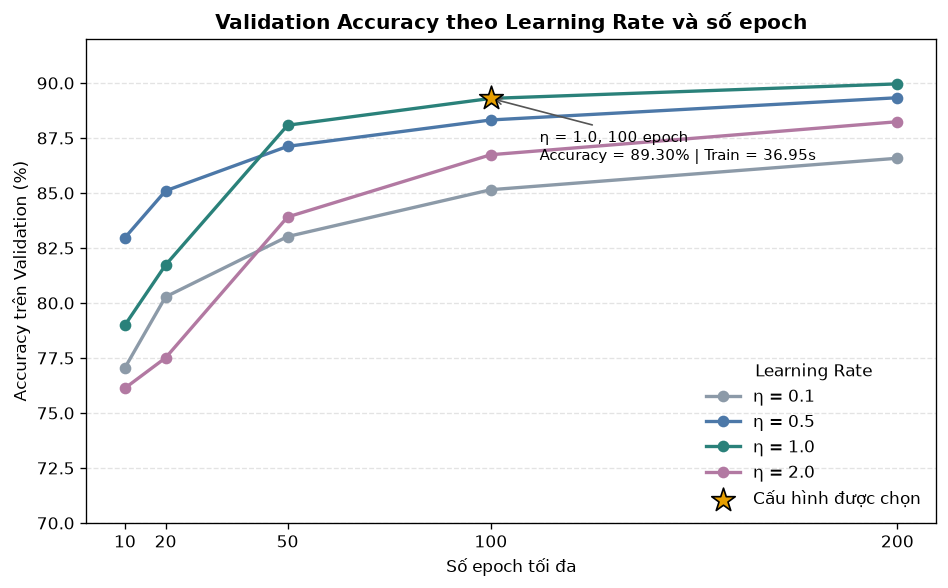

In [9]:
epochs = [10, 20, 50, 100, 200]

accuracy_by_lr = {
    0.1: [77.06, 80.28, 83.02, 85.15, 86.58],
    0.5: [82.97, 85.10, 87.12, 88.32, 89.33],
    1.0: [79.00, 81.73, 88.08, 89.30, 89.96],
    2.0: [76.13, 77.51, 83.91, 86.74, 88.24],
}

colors = {
    0.1: "#8C9AA8",
    0.5: "#4C78A8",
    1.0: "#2A817A",
    2.0: "#B279A2",
}

fig, ax = plt.subplots(figsize=(8, 5))

for eta, accuracies in accuracy_by_lr.items():
    ax.plot(
        epochs, accuracies,
        marker="o", linewidth=2, markersize=6,
        color=colors[eta], label=f"η = {eta}"
    )

# Cấu hình được chọn: eta = 1.0, 100 epoch
ax.scatter(
    100, 89.30, marker="*", s=220,
    color="#E69F00", edgecolor="black",
    zorder=5, label="Cấu hình được chọn"
)

ax.annotate(
    "η = 1.0, 100 epoch\nAccuracy = 89.30% | Train = 36.95s",
    xy=(100, 89.30),
    xytext=(112, 86.5),
    arrowprops={"arrowstyle": "->", "color": "#555"},
    fontsize=9
)

ax.set_title("Validation Accuracy theo Learning Rate và số epoch",
             fontweight="bold")
ax.set_xlabel("Số epoch tối đa")
ax.set_ylabel("Accuracy trên Validation (%)")
ax.set_xticks(epochs)
ax.set_ylim(70, 92)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Learning Rate", frameon=False)

fig.tight_layout()
fig_path = FIGURES_DIR / "2_01_logistic_tuning_lr_epochs.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
plt.show()

## **5. Huấn luyện mô hình tối ưu**

Sau khi xác định siêu tham số tối ưu $\eta^*$ = 1.0, max_epochs = 100, ta tiến hành:
1. Huấn luyện mô hình One-vs-Rest chính thức trên toàn bộ $50.000$ mẫu tập Train với `max_epochs = 100`.
2. Trực quan hoá **Đường cong hội tụ hàm mất mát (Loss Curve)** trung bình của 10 mô hình nhị phân qua các epoch (**Biểu đồ 2**).
3. Ghép véc-tơ trọng số của 10 mô hình con thành ma trận trọng số $\mathbf{W} \in \mathbb{R}^{785 \times 10}$, tái cấu trúc thành 10 ảnh kích thước $28 \times 28$ để quan sát **Bản đồ nhiệt khuôn mẫu nhận thức 10 chữ số** (**Biểu đồ 3**).



In [10]:
# HUẤN LUYỆN MÔ HÌNH TỐI ƯU & ĐO ĐẠC THỜI GIAN
best_lr = 1.0
max_epochs = 100

print(f"--- HUẤN LUYỆN LOGISTIC REGRESSION ONE-VS-REST TỐI ƯU (eta = {best_lr}, max_epochs = {max_epochs}) ---")

# 1. Huấn luyện mô hình chính thức và đo thời gian khớp dữ liệu (fit)
t0 = time.perf_counter()
model_opt = OneVsRest(eta=best_lr, lam=1e-4, max_epochs=max_epochs)
model_opt.fit(X_train, y_train)
t_fit_lr = time.perf_counter() - t0

# 2. Đo thời gian dự đoán trên tập Huấn luyện (50.000 mẫu)
t0 = time.perf_counter()
preds_train_lr = model_opt.predict(X_train)
t_pred_train_lr = time.perf_counter() - t0

# 3. Đo thời gian dự đoán trên tập Kiểm định (10.000 mẫu)
t0 = time.perf_counter()
preds_val_lr = model_opt.predict(X_val)
t_pred_val_lr = time.perf_counter() - t0

# 4. Đo thời gian dự đoán trên tập Kiểm thử (10.000 mẫu)
t0 = time.perf_counter()
preds_test_lr = model_opt.predict(X_test)
t_pred_test_lr = time.perf_counter() - t0

# 5. Tính toán độ chính xác Accuracy (%) trên cả 3 tập
acc_train_lr = accuracy_score(y_train, preds_train_lr) * 100
acc_val_lr   = accuracy_score(y_val, preds_val_lr) * 100
acc_test_lr  = accuracy_score(y_test, preds_test_lr) * 100

print(f"✔ Huấn luyện 10 bộ phân lớp hoàn tất trong : {t_fit_lr:.3f} giây")
print(f"  - Train Accuracy (50.000 mẫu) : {acc_train_lr:.2f}% | Suy luận: {t_pred_train_lr:.3f}s")
print(f"  - Val Accuracy   (10.000 mẫu) : {acc_val_lr:.2f}% | Suy luận: {t_pred_val_lr:.3f}s")
print(f"  - Test Accuracy  (10.000 mẫu) : {acc_test_lr:.2f}% | Suy luận: {t_pred_test_lr:.3f}s")


--- HUẤN LUYỆN LOGISTIC REGRESSION ONE-VS-REST TỐI ƯU (eta = 1.0, max_epochs = 100) ---
✔ Huấn luyện 10 bộ phân lớp hoàn tất trong : 32.288 giây
  - Train Accuracy (50.000 mẫu) : 89.48% | Suy luận: 0.132s
  - Val Accuracy   (10.000 mẫu) : 89.30% | Suy luận: 0.028s
  - Test Accuracy  (10.000 mẫu) : 90.18% | Suy luận: 0.026s


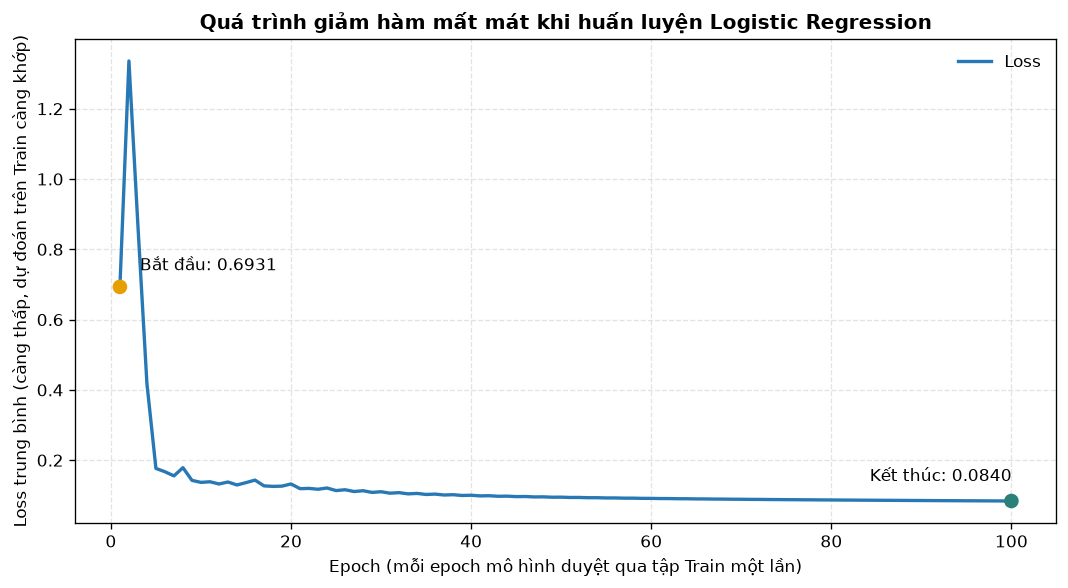

In [11]:
losses = model_opt.loss_history_
epochs = np.arange(1, len(losses) + 1)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(epochs, losses, color="#2878B5", linewidth=2, label="Loss")
ax.scatter([epochs[0], epochs[-1]], [losses[0], losses[-1]],
           color=["#E69F00", "#2A817A"], s=60, zorder=3)

ax.annotate(
    f"Bắt đầu: {losses[0]:.4f}",
    xy=(epochs[0], losses[0]),
    xytext=(12, 10), textcoords="offset points"
)
ax.annotate(
    f"Kết thúc: {losses[-1]:.4f}",
    xy=(epochs[-1], losses[-1]),
    xytext=(-85, 12), textcoords="offset points"
)

ax.set_title("Quá trình giảm hàm mất mát khi huấn luyện Logistic Regression",
             fontweight="bold")
ax.set_xlabel("Epoch (mỗi epoch mô hình duyệt qua tập Train một lần)")
ax.set_ylabel("Loss trung bình (càng thấp, dự đoán trên Train càng khớp)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(frameon=False)

fig.tight_layout()
fig_path = FIGURES_DIR / "2_02_logistic_loss_curve.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
plt.show()

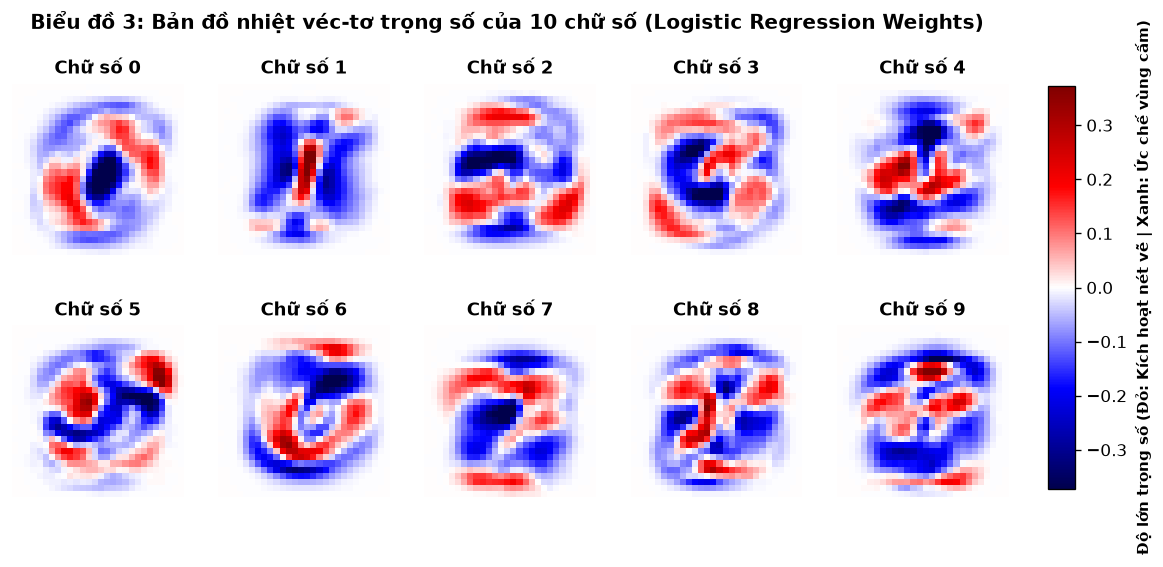

In [12]:
# (Biểu đồ 3 - Logistic): BẢN ĐỒ NHIỆT VÉC-TƠ TRỌNG SỐ W (28x28)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

weights_matrix = model_opt.W_[:-1, :]
vmax_abs = np.percentile(np.abs(weights_matrix), 99)

for c in range(10):
    w_digit = weights_matrix[:, c].reshape(28, 28)  
    im = axes[c].imshow(w_digit, cmap="seismic", vmin=-vmax_abs, vmax=vmax_abs)
    axes[c].set_title(f"Chữ số {c}", fontsize=11, fontweight="bold")
    axes[c].axis("off")

fig.subplots_adjust(right=0.88, wspace=0.2, hspace=0.2)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Độ lớn trọng số (Đỏ: Kích hoạt nét vẽ | Xanh: Ức chế vùng cấm)", fontsize=9, fontweight="bold")

plt.suptitle("Biểu đồ 3: Bản đồ nhiệt véc-tơ trọng số của 10 chữ số (Logistic Regression Weights)", fontsize=12, fontweight="bold", y=0.98)

# Lưu hình ảnh vào figures/
fig_path_3 = FIGURES_DIR / "2_03_logistic_weights.png"
plt.savefig(fig_path_3, bbox_inches="tight", dpi=150)
plt.show()

---
## **6. Đối chiếu kiểm chứng với thư viện Scikit-Learn**
1. Huấn luyện mô hình `OneVsRestClassifier(LogisticRegression(solver='lbfgs', max_iter=50))` từ thư viện Scikit-Learn trên tập đối chiếu.
2. So sánh độ chính xác Test Accuracy giữa mã nguồn tự viết From Scratch và thư viện chuẩn Scikit-Learn.
3. Tính toán tỷ lệ đồng thuận dự đoán giữa hai cài đặt trên 10.000 mẫu Test.



In [13]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# 1. Huấn luyện mô hình One-vs-Rest chuẩn của Scikit-Learn trên tập đối chiếu 10.000 mẫu
t0 = time.perf_counter()
sk_ovr = OneVsRestClassifier(SklearnLogisticRegression(C=1.0, max_iter=50, random_state=SEED, solver="lbfgs"))
sk_ovr.fit(X_train[:10000], y_train[:10000])
t_fit_sk = time.perf_counter() - t0

# 2. Đánh giá độ chính xác của Scikit-Learn trên toàn bộ 10.000 mẫu Test
preds_test_sk = sk_ovr.predict(X_test)
acc_test_sk = accuracy_score(y_test, preds_test_sk) * 100

# 3. Tính tỷ lệ đồng thuận
agreement_rate = np.mean(preds_test_lr == preds_test_sk) * 100

df_compare_lr = pd.DataFrame({
    "Phương pháp": ["Tự cài đặt (From Scratch OvR Batch GD)", "Thư viện chuẩn (Scikit-Learn OneVsRest)"],
    "Dữ liệu huấn luyện": ["Toàn bộ 50.000 mẫu", "10.000 mẫu đối chiếu"],
    "Test Accuracy (%)": [f"{acc_test_lr:.2f}%", f"{acc_test_sk:.2f}%"],
    "Thời gian huấn luyện (s)": [f"{t_fit_lr:.2f}s", f"{t_fit_sk:.2f}s"],
    "Độ chênh lệch tuyệt đối": ["-", f"{abs(acc_test_lr - acc_test_sk):.2f}%"]
})

print("--- Đối chiếu kiểm chứng Logistic Regression với Scikit-Learn ---")
display(df_compare_lr)
print(f"Tỷ lệ dự đoán đồng thuận giữa 2 cài đặt: {agreement_rate:.2f}%")


c:\Users\Lenovo\Downloads\Pattern-Recognition\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\Lenovo\Downloads\Pattern-Recognition\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.or

--- Đối chiếu kiểm chứng Logistic Regression với Scikit-Learn ---


d:\HK1_nam3\Nhận dạng mẫu\Thực hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
d:\HK1_nam3\Nhận dạng mẫu\Thực hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

,Phương pháp,Dữ liệu huấn luyện,Test Accuracy (%),Thời gian huấn luyện (s),Độ chênh lệch tuyệt đối
0,Tự cài đặt (From Scratch OvR Batch GD),Toàn bộ 50.000 mẫu,90.18%,32.29s,-
1,Thư viện chuẩn (Scikit-Learn OneVsRest),10.000 mẫu đối chiếu,90.59%,1.56s,0.41%


Tỷ lệ dự đoán đồng thuận giữa 2 cài đặt: 93.27%


---
## **7. Đánh giá toàn diện mô hình Logistic Regression trên 3 tập dữ liệu**

Thực hiện đánh giá đầy đủ và độc lập hiệu năng của mô hình Logistic Regression One-vs-Rest:
1. Bảng tổng hợp 6 chỉ số định lượng trên cả 3 tập: Train (50.000 mẫu), Validation (10.000 mẫu), Test (10.000 mẫu).
2. Vẽ 3 Ma trận nhầm lẫn (Confusion Matrix) cho Train (Biểu đồ 4), Validation (Biểu đồ 5), Test (Biểu đồ 6)
3. Bảng phân tích chi tiết hiệu năng của từng chữ số trên tập Test (TP, FP, FN, Precision, Recall, F1, Support).
4. Lưới trực quan hóa các mẫu ảnh nhận diện sai điển hình (**Biểu đồ 7**).



In [14]:
# TÍNH TOÁN ĐẦY ĐỦ 6 ĐỘ ĐO CHUẨN MỰC TRÊN CẢ 3 TẬP
# - Bao gồm: Accuracy, Macro Precision, Macro Recall, Macro F1, Train Time, Inference Time.
def compute_lr_metrics(y_true, y_pred, t_fit, t_infer):
    return {
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Macro Precision (%)": round(precision_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Macro Recall (%)": round(recall_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Macro F1 (%)": round(f1_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Train Time (s)": round(t_fit, 3) if t_fit > 0 else "-",
        "Inference Time (s)": round(t_infer, 3)
    }

# Lập bảng tổng hợp cho cả 3 tập dữ liệu
df_metrics_lr = pd.DataFrame([
    compute_lr_metrics(y_train, preds_train_lr, t_fit_lr, t_pred_train_lr),
    compute_lr_metrics(y_val, preds_val_lr, 0.0, t_pred_val_lr),
    compute_lr_metrics(y_test, preds_test_lr, 0.0, t_pred_test_lr)
], index=["Train (50.000 mẫu)", "Validation (10.000 mẫu)", "Test (10.000 mẫu)"])

print("--- BẢNG TỔNG HỢP HIỆU NĂNG LOGISTIC REGRESSION ---")
display(df_metrics_lr)


--- BẢNG TỔNG HỢP HIỆU NĂNG LOGISTIC REGRESSION ---


,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Train Time (s),Inference Time (s)
Train (50.000 mẫu),89.48,89.43,89.30,89.30,32.288,0.132
Validation (10.000 mẫu),89.30,89.18,89.08,89.10,-,0.028
Test (10.000 mẫu),90.18,90.17,90.03,90.03,-,0.026


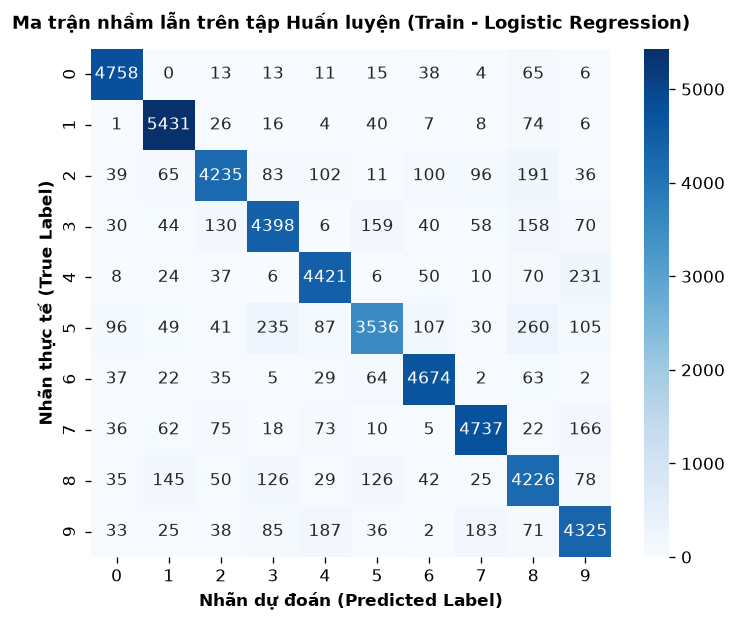

In [15]:
cm_train_lr = confusion_matrix(y_train, preds_train_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_train_lr, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Ma trận nhầm lẫn trên tập Huấn luyện (Train - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_4 = FIGURES_DIR / "2_04_logistic_confusion_train.png"
plt.savefig(fig_path_4, bbox_inches="tight", dpi=150)
plt.show()


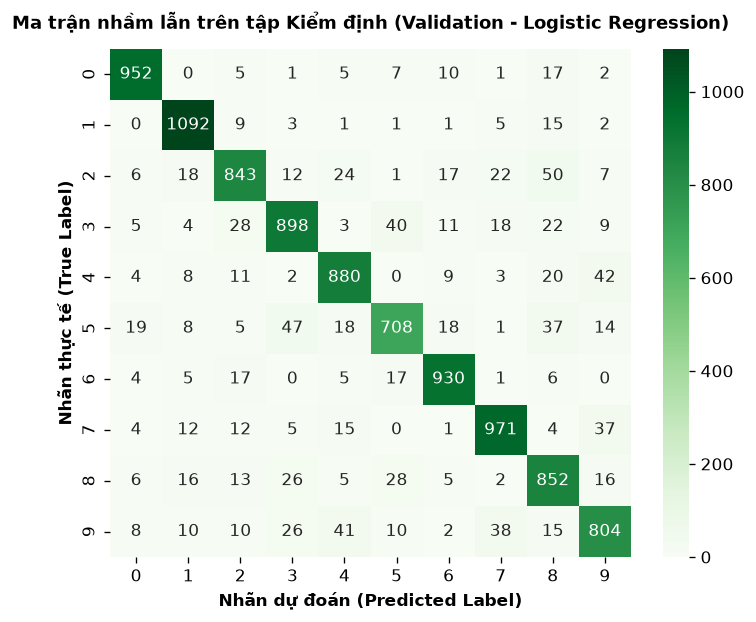

In [18]:
# (Biểu đồ 5 - Logistic): MA TRẬN NHẦM LẪN TẬP KIỂM ĐỊNH (VALIDATION)

cm_val_lr = confusion_matrix(y_val, preds_val_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_val_lr, annot=True, fmt="d", cmap="Greens", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Ma trận nhầm lẫn trên tập Kiểm định (Validation - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_5 = FIGURES_DIR / "2_05_logistic_confusion_val.png"
plt.savefig(fig_path_5, bbox_inches="tight", dpi=150)
plt.show()

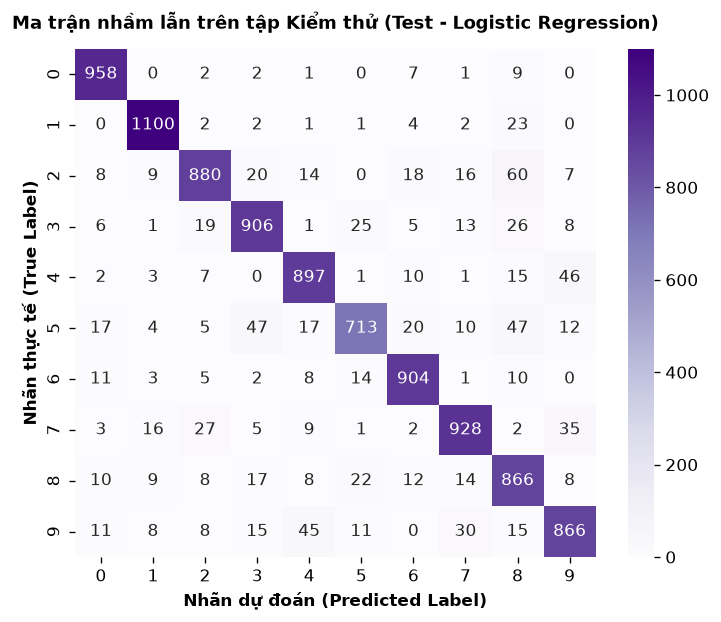

In [17]:
# (Biểu đồ 6 - Logistic): MA TRẬN NHẦM LẪN TẬP KIỂM THỬ (TEST)

cm_test_lr = confusion_matrix(y_test, preds_test_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_test_lr, annot=True, fmt="d", cmap="Purples", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Ma trận nhầm lẫn trên tập Kiểm thử (Test - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_6 = FIGURES_DIR / "2_06_logistic_confusion_test.png"
plt.savefig(fig_path_6, bbox_inches="tight", dpi=150)
plt.show()


In [18]:
# BẢNG PHÂN TÍCH HIỆU NĂNG CHI TIẾT TỪNG CHỮ SỐ (TEST SET)
digit_records_lr = []
total_test_samples = len(y_test)

for c in range(10):
    tp = int(cm_test_lr[c, c])                                   
    fn = int(np.sum(cm_test_lr[c, :]) - tp)                          
    fp = int(np.sum(cm_test_lr[:, c]) - tp)                        
    tn = int(total_test_samples - tp - fn - fp)                    
    
    prec = tp / (tp + fp) * 100 if (tp + fp) > 0 else 0.0          
    rec  = tp / (tp + fn) * 100 if (tp + fn) > 0 else 0.0            
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0 
    support = tp + fn                                           
    
    digit_records_lr.append({
        "Chữ số": c,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F1-score (%)": round(f1, 2),
        "Số mẫu (Support)": support
    })

df_digits_lr = pd.DataFrame(digit_records_lr)
print("--- BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (LOGISTIC REGRESSION) ---")
display(df_digits_lr)


--- BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (LOGISTIC REGRESSION) ---


,Chữ số,TP,FP,FN,TN,Precision (%),Recall (%),F1-score (%),Số mẫu (Support)
0,0,958,68,22,8952,93.37,97.76,95.51,980
1,1,1100,53,35,8812,95.40,96.92,96.15,1135
2,2,880,83,152,8885,91.38,85.27,88.22,1032
3,3,906,110,104,8880,89.17,89.70,89.44,1010
4,4,897,104,85,8914,89.61,91.34,90.47,982
5,5,713,75,179,9033,90.48,79.93,84.88,892
6,6,904,78,54,8964,92.06,94.36,93.20,958
7,7,928,88,100,8884,91.34,90.27,90.80,1028
8,8,866,207,108,8819,80.71,88.91,84.61,974
9,9,866,116,143,8875,88.19,85.83,86.99,1009


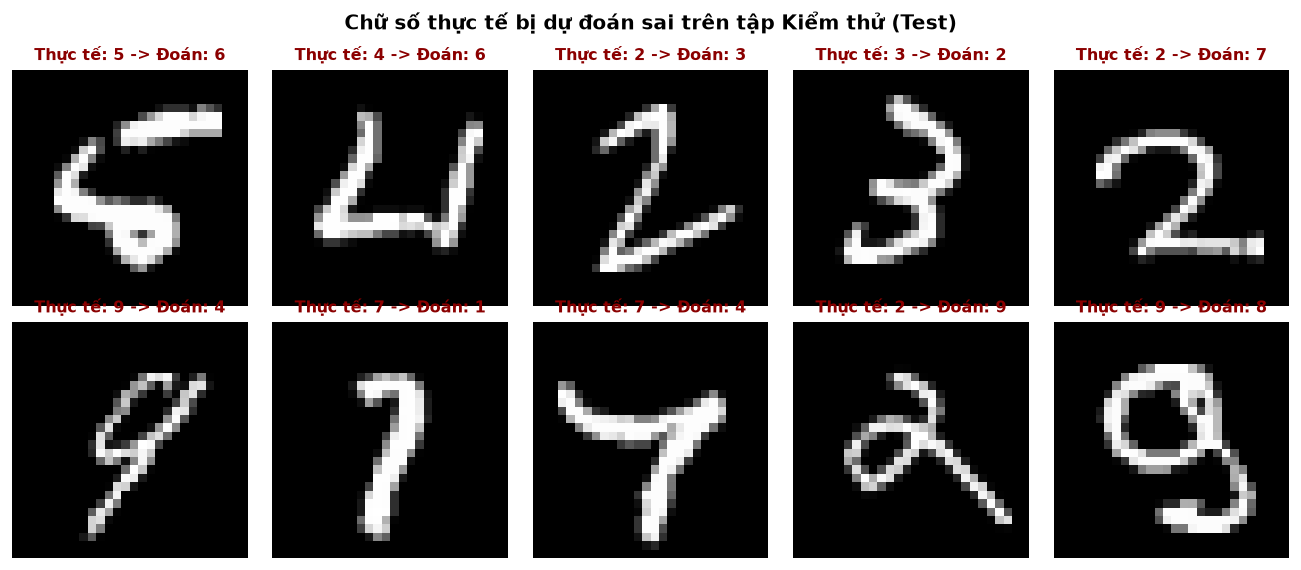

In [19]:
# Biểu đồ 7 - Logistic): LƯỚI TRỰC QUAN HÓA CÁC MẪU DỰ ĐOÁN SAI
mis_indices_lr = np.where(preds_test_lr != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

for idx_plot, mis_idx in enumerate(mis_indices_lr[:10]):
    img = X_test[mis_idx].reshape(28, 28)     # Định hình lại mảng pixel thành ảnh 28x28
    true_label = y_test[mis_idx]
    pred_label = preds_test_lr[mis_idx]
    
    axes[idx_plot].imshow(img, cmap="gray")
    axes[idx_plot].set_title(f"Thực tế: {true_label} -> Đoán: {pred_label}",
                             fontsize=9.5, fontweight="bold", color="darkred")
    axes[idx_plot].axis("off")

plt.suptitle("Chữ số thực tế bị dự đoán sai trên tập Kiểm thử (Test)", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout()

fig_path_7 = FIGURES_DIR / "2_07_logistic_misclassified_samples.png"
plt.savefig(fig_path_7, bbox_inches="tight", dpi=150)
plt.show()


### **Nhận xét định lượng và phân tích kết quả thực nghiệm Logistic Regression**
#### **7.1. Hiệu năng tổng thể và khả năng tổng quát hóa**

Mô hình được huấn luyện với cấu hình đã chọn **$\eta = 1.0$, `max_epochs = 100`**. Kết quả tổng hợp:

| Tập dữ liệu | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| Train (50.000 mẫu) | 89.48% | 89.43% | 89.30% | 89.30% |
| Validation (10.000 mẫu) | 89.30% | 89.18% | 89.08% | 89.10% |
| Test (10.000 mẫu) | 90.18% | 90.17% | 90.03% | 90.03% |

Thời gian huấn luyện là khoảng **37,38 giây**. Dự đoán mất khoảng **0,153 giây trên Train** và **0,030 giây trên mỗi tập Validation/Test gồm 10.000 ảnh**. Thời gian thực tế có thể thay đổi tùy máy tính và môi trường chạy.

Accuracy của Train và Validation chỉ chênh **0,18 điểm phần trăm**; Test cao hơn Train **0,70 điểm phần trăm**. Các kết quả khá gần nhau, cho thấy chưa có khoảng cách rõ rệt giữa hiệu năng trên Train và Validation. Tuy nhiên, chỉ dựa vào các con số này không thể khẳng định mô hình hoàn toàn không overfit; tập Test vẫn là căn cứ đánh giá cuối cùng trên dữ liệu chưa dùng để chọn tham số.

#### **7.2. Khả năng nhận diện từng chữ số**

- **Nhận diện tốt nhất:** Chữ số **1** có F1-score cao nhất (**96,15%**), tiếp theo là chữ số **0** (**95,51%**) và chữ số **6** (**93,20%**). Riêng số 0 có Recall **97,76%** (mô hình nhận đúng 958/980 mẫu); số 1 có Recall **96,92%** (1.100/1.135 mẫu).
- **Khó nhận diện hơn:** Chữ số **8** có F1-score thấp nhất (**84,61%**) và Precision thấp nhất (**80,71%**); có 207 mẫu thuộc lớp khác bị dự đoán thành số 8. Chữ số **5** có Recall thấp nhất (**79,93%**), tức mô hình bỏ sót 179/892 mẫu số 5.
- Chữ số **2** cũng còn bị bỏ sót tương đối nhiều: Recall **85,27%**, với 152 mẫu bị dự đoán sang lớp khác.

Như vậy, mô hình phân biệt tốt các chữ số có hình dạng đặc trưng như 0 và 1, nhưng dễ nhầm hơn ở các chữ số có kiểu nét viết đa dạng hoặc có hình dạng tương tự chữ số khác.

#### **7.3. Các lỗi nhầm lẫn nổi bật trên tập Test** 

Ma trận nhầm lẫn cho thấy những cặp dự đoán sai xuất hiện nhiều gồm:

1. **Số 2 bị dự đoán thành số 8: 60 mẫu.**
2. **Số 5 bị dự đoán thành số 3: 47 mẫu** và **thành số 8: 47 mẫu**.
3. **Số 4 bị dự đoán thành số 9: 46 mẫu**; ngược lại, **số 9 bị dự đoán thành số 4: 45 mẫu**.

Các ví dụ trong lưới ảnh dự đoán sai cũng cho thấy một số chữ số viết tay có nét biến dạng, thiếu nét hoặc hình dạng dễ gần với lớp khác, chẳng hạn 5→6, 4→6, 2→3 và 3→2. Những trường hợp này giúp minh họa cụ thể các giới hạn mà thống kê trong ma trận nhầm lẫn thể hiện.

#### **7.4. Giới hạn của Logistic Regression và hướng phát triển**

Trong cài đặt này, Logistic Regression tính điểm số từ tổ hợp tuyến tính của các pixel, tức học ranh giới phân loại dạng tuyến tính. Mô hình xử lý ảnh như một vector pixel nên chưa biểu diễn tốt các quan hệ không gian phức tạp giữa những nét ở các vị trí lân cận.

Điều đó có thể góp phần gây khó khăn khi phân biệt các chữ số có nét tương tự hoặc biến dạng. Kết quả Test đạt **90,18%**, là một mốc cơ sở hữu ích để so sánh với các mô hình tiếp theo. MLP có thể học các quan hệ phi tuyến, còn CNN khai thác cấu trúc không gian của ảnh; nhóm có thể đối chiếu kết quả của các mô hình này trên cùng cách chia Train/Validation/Test.

## **8. Xuất kết quả thực nghiệm**


In [21]:
# - Xuất bảng chỉ số thực nghiệm 3 tập ra results/2_Logistic_metrics.csv.

# 1. Xuất file CSV metrics 3 tập 
logistic_csv_records = [
    {
        "model": "LogisticRegression-NP",
        "split": "train",
        "accuracy": round(float(accuracy_score(y_train, preds_train_lr)), 5),
        "precision_macro": round(float(precision_score(y_train, preds_train_lr, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_train, preds_train_lr, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_train, preds_train_lr, average="macro")), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_train_lr), 4),
        "n_samples": int(len(y_train)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs=100,lam=1e-4,strategy=OneVsRest"
    },
    {
        "model": "LogisticRegression-NP",
        "split": "validation",
        "accuracy": round(float(accuracy_score(y_val, preds_val_lr)), 5),
        "precision_macro": round(float(precision_score(y_val, preds_val_lr, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_val, preds_val_lr, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_val, preds_val_lr, average="macro")), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_val_lr), 4),
        "n_samples": int(len(y_val)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs=100,lam=1e-4,strategy=OneVsRest"
    },
    {
        "model": "LogisticRegression-NP",
        "split": "test",
        "accuracy": round(float(accuracy_score(y_test, preds_test_lr)), 5),
        "precision_macro": round(float(precision_score(y_test, preds_test_lr, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_test, preds_test_lr, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_test, preds_test_lr, average="macro")), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_test_lr), 4),
        "n_samples": int(len(y_test)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs=100,lam=1e-4,strategy=OneVsRest"
    }
]

df_logistic_metrics = pd.DataFrame(logistic_csv_records)
csv_logreg_path = RESULTS_DIR / "2_Logistic_metrics.csv"
df_logistic_metrics.to_csv(csv_logreg_path, index=False)
print(f"✔ Đã lưu bảng chỉ số thực nghiệm vào: '{csv_logreg_path}'")
display(df_logistic_metrics)

# 2. Xuất file nén artifacts (.npz) lưu trữ checkpoint mô hình
logreg_artifacts_path = ARTIFACTS_DIR / "2_logistic_results.npz"

proba_val_lr  = model_opt.predict_proba(X_val)
proba_test_lr = model_opt.predict_proba(X_test)
W_matrix_all  = np.column_stack([m.w_ for m in model_opt.models_])

np.savez_compressed(
    logreg_artifacts_path,
    W=W_matrix_all,
    classes=model_opt.classes_,
    best_lr=best_lr,
    preds_train=preds_train_lr,
    preds_val=preds_val_lr,
    preds_test=preds_test_lr,
    proba_val=proba_val_lr,
    proba_test=proba_test_lr,
    acc_train=acc_train_lr,
    acc_val=acc_val_lr,
    acc_test=acc_test_lr
)
print(f"✔ Đã lưu trữ checkpoint Logistic Regression vào: '{logreg_artifacts_path}' ({os.path.getsize(logreg_artifacts_path)/(1024):.1f} KB)")


✔ Đã lưu bảng chỉ số thực nghiệm vào: 'C:\Users\Lenovo\Downloads\Pattern-Recognition\results\2_Logistic_metrics.csv'


,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,LogisticRegression-NP,train,0.89482,0.89429,0.89297,0.89303,32.2878,0.1321,50000,42,"eta=1.0,max_epochs=100,lam=1e-4,strategy=OneVs..."
1,LogisticRegression-NP,validation,0.89300,0.89181,0.89080,0.89095,32.2878,0.0276,10000,42,"eta=1.0,max_epochs=100,lam=1e-4,strategy=OneVs..."
2,LogisticRegression-NP,test,0.90180,0.90171,0.90030,0.90028,32.2878,0.0259,10000,42,"eta=1.0,max_epochs=100,lam=1e-4,strategy=OneVs..."


✔ Đã lưu trữ checkpoint Logistic Regression vào: 'C:\Users\Lenovo\Downloads\Pattern-Recognition\artifacts\2_logistic_results.npz' (1600.2 KB)
